In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.applications import EfficientNetB0
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_class_weight
import os, glob

print("TF Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TF Version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# ============================================================
# CELL 1: Imports
# ============================================================
!pip install -q kagglehub

import kagglehub
import os, glob
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.applications import EfficientNetB0
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_class_weight

print("TF Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TF Version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
# ============================================================
# CELL 2: Download Dataset
# ============================================================
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
print("Dataset downloaded to:", path)
print("Contents:", os.listdir(path))

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Dataset downloaded to: /kaggle/input/brain-tumor-mri-dataset
Contents: ['Training', 'Testing']


In [4]:
# ============================================================
# CELL 3: Auto-detect Training/Testing folders
# ============================================================
def find_dir(base_path, folder_name):
    for root, dirs, files in os.walk(base_path):
        if folder_name in dirs:
            return os.path.join(root, folder_name)
    return None

TRAIN_DIR = find_dir(path, "Training")
TEST_DIR  = find_dir(path, "Testing")

print("TRAIN_DIR:", TRAIN_DIR)
print("TEST_DIR:", TEST_DIR)
assert TRAIN_DIR and TEST_DIR, "Folders not found — check dataset structure!"

print("Classes:", os.listdir(TRAIN_DIR))
print("Train images:", len(glob.glob(f"{TRAIN_DIR}/**/*.jpg", recursive=True)))
print("Test images:", len(glob.glob(f"{TEST_DIR}/**/*.jpg", recursive=True)))

TRAIN_DIR: /kaggle/input/brain-tumor-mri-dataset/Training
TEST_DIR: /kaggle/input/brain-tumor-mri-dataset/Testing
Classes: ['pituitary', 'notumor', 'meningioma', 'glioma']
Train images: 5600
Test images: 1600


In [5]:
# ============================================================
# CELL 4: Data Pipeline
# ============================================================
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.15, subset="training", seed=42,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.15, subset="validation", seed=42,
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='categorical'
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode='categorical', shuffle=False
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)

# Class weights for imbalance handling
labels = []
for _, y in train_ds.unbatch():
    labels.append(np.argmax(y.numpy()))
class_weights = compute_class_weight('balanced', classes=np.unique(labels), y=labels)
class_weights = dict(enumerate(class_weights))
print("Class weights:", class_weights)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

Found 5600 files belonging to 4 classes.
Using 4760 files for training.
Found 5600 files belonging to 4 classes.
Using 840 files for validation.
Found 1600 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Class weights: {0: np.float64(0.9859154929577465), 1: np.float64(0.9966499162479062), 2: np.float64(1.015358361774744), 3: np.float64(1.0025273799494523)}


In [6]:
# ============================================================
# CELL 5: Data Augmentation
# ============================================================
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="augmentation")

In [7]:
# ============================================================
# CELL 6: Build Model (EfficientNetB0 Transfer Learning)
# ============================================================
base_model = EfficientNetB0(include_top=False, weights='imagenet', input_shape=(224,224,3))
base_model.trainable = False

inputs = tf.keras.Input(shape=(224,224,3))
x = data_augmentation(inputs)
x = tf.keras.applications.efficientnet.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(256, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

model = models.Model(inputs, outputs)
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall')]
)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,383,655 (16.72 MB)

 Trainable params: 331,524 (1.26 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [8]:
# ============================================================
# CELL 7: Callbacks
# ============================================================
early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True, verbose=1)
reduce_lr = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3, min_lr=1e-7, verbose=1)
checkpoint = callbacks.ModelCheckpoint('best_model_stage1.keras', monitor='val_accuracy', save_best_only=True, verbose=1)

In [9]:
# ============================================================
# CELL 8: Stage 1 Training (Frozen Base)
# ============================================================
history1 = model.fit(
    train_ds, validation_data=val_ds, epochs=25,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr, checkpoint]
)

Epoch 1/25
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.6935 - loss: 1.0072 - precision: 0.7155 - recall: 0.6741
Epoch 1: val_accuracy improved from None to 0.81786, saving model to best_model_stage1.keras

Epoch 1: finished saving model to best_model_stage1.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 42s 116ms/step - accuracy: 0.7632 - loss: 0.7806 - precision: 0.7795 - recall: 0.7492 - val_accuracy: 0.8179 - val_loss: 0.5046 - val_precision: 0.8556 - val_recall: 0.7690 - learning_rate: 0.0010
Epoch 2/25
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.8176 - loss: 0.5562 - precision: 0.8267 - recall: 0.8080
Epoch 2: val_accuracy improved from 0.81786 to 0.86310, saving model to best_model_stage1.keras

Epoch 2: finished saving model to best_model_stage1.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 13s 89ms/step - accuracy: 0.8271 - loss: 0.5388 - precision: 0.8360 - recall: 0.8172 - val_accuracy: 0.8631 - val_loss: 0.3757 - val_precision: 0.8859 - val_recall: 0.8500 - learning_rate: 0

In [10]:
# ============================================================
# CELL 9: Stage 2 - Fine-Tuning
# ============================================================
base_model.trainable = True
for layer in base_model.layers[:100]:
    layer.trainable = False

model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall')]
)

early_stop_ft = callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True, verbose=1)
checkpoint_ft = callbacks.ModelCheckpoint('best_model_final.keras', monitor='val_accuracy', save_best_only=True, verbose=1)

history2 = model.fit(
    train_ds, validation_data=val_ds, epochs=30,
    class_weight=class_weights,
    callbacks=[early_stop_ft, reduce_lr, checkpoint_ft]
)

Epoch 1/30
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step - accuracy: 0.6924 - loss: 0.9186 - precision: 0.7117 - recall: 0.6612
Epoch 1: val_accuracy improved from None to 0.83571, saving model to best_model_final.keras

Epoch 1: finished saving model to best_model_final.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 58s 199ms/step - accuracy: 0.7158 - loss: 0.8332 - precision: 0.7365 - recall: 0.6887 - val_accuracy: 0.8357 - val_loss: 0.4601 - val_precision: 0.8545 - val_recall: 0.8250 - learning_rate: 1.0000e-05
Epoch 2/30
149/149 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step - accuracy: 0.7773 - loss: 0.6458 - precision: 0.7951 - recall: 0.7616
Epoch 2: val_accuracy improved from 0.83571 to 0.85119, saving model to best_model_final.keras

Epoch 2: finished saving model to best_model_final.keras
149/149 ━━━━━━━━━━━━━━━━━━━━ 27s 182ms/step - accuracy: 0.7901 - loss: 0.6194 - precision: 0.8087 - recall: 0.7729 - val_accuracy: 0.8512 - val_loss: 0.4466 - val_precision: 0.8734 - val_recall: 0.8381 - learning_rate

              precision    recall  f1-score   support

      glioma     0.8675    0.6875    0.7671       400
  meningioma     0.8099    0.5750    0.6725       400
     notumor     0.8419    0.9850    0.9078       400
   pituitary     0.7439    0.9875    0.8485       400

    accuracy                         0.8087      1600
   macro avg     0.8158    0.8088    0.7990      1600
weighted avg     0.8158    0.8087    0.7990      1600

F1 macro: 0.7989959360670861
F1 weighted: 0.7989959360670861


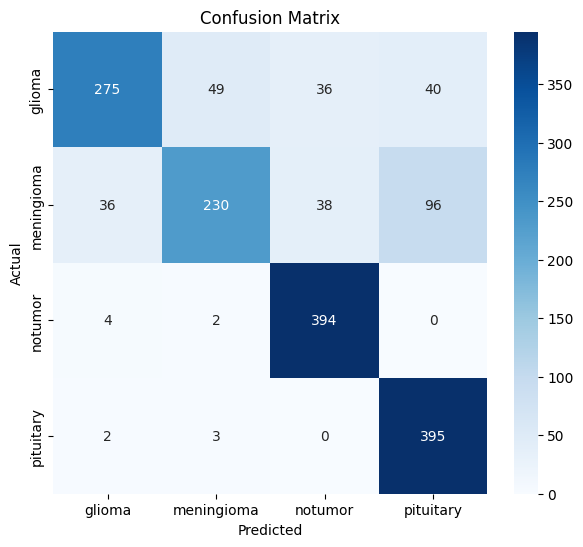

In [11]:
# ============================================================
# CELL 10: Evaluation
# ============================================================
model.load_weights('best_model_final.keras')

y_true, y_pred = [], []
for images, labels_batch in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels_batch.numpy(), axis=1))

print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
print("F1 macro:", f1_score(y_true, y_pred, average='macro'))
print("F1 weighted:", f1_score(y_true, y_pred, average='weighted'))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion Matrix')
plt.show()

In [12]:
# ============================================================
# CELL 11: Save Model
# ============================================================
model.save('quantum_tumor_sensor_model.keras')
print("Saved successfully!")

Saved successfully!
